# Stacking Classifier from Scratch

## Objectives
- Understand stacking ensemble learning.
- Train multiple base classifiers.
- Generate out-of-fold predictions without data leakage.
- Train a meta-model using base-model predictions.
- Compare the scratch implementation with Scikit-Learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    n_classes=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (800, 6)
Testing shape: (200, 6)


In [3]:
base_models = [
    ("knn", make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    )),
    ("logistic", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ))
]

meta_model = LogisticRegression(max_iter=1000)

In [4]:
class StackingClassifierScratch:
    def __init__(self, base_models, meta_model, n_folds=5):
        self.base_models = base_models
        self.meta_model = meta_model
        self.n_folds = n_folds

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        self.classes_ = np.unique(y)

        if len(self.classes_) < 2:
            raise ValueError("Training data must contain at least two classes.")

        counts = np.unique(y, return_counts=True)[1]
        if counts.min() < self.n_folds:
            raise ValueError(
                "Each class must have at least n_folds examples."
            )

        cv = StratifiedKFold(
            n_splits=self.n_folds,
            shuffle=True,
            random_state=42
        )

        # One probability column per base model for binary classification.
        if len(self.classes_) != 2:
            raise ValueError(
                "This educational implementation currently supports binary classification."
            )

        oof_predictions = np.zeros(
            (len(y), len(self.base_models)),
            dtype=float
        )

        self.fitted_base_models_ = []

        for model_index, (_, model) in enumerate(self.base_models):
            for train_idx, valid_idx in cv.split(X, y):
                fold_model = clone(model)
                fold_model.fit(X[train_idx], y[train_idx])

                positive_col = np.where(
                    fold_model.classes_ == self.classes_[1]
                )[0][0]

                oof_predictions[valid_idx, model_index] = (
                    fold_model.predict_proba(X[valid_idx])[:, positive_col]
                )

            # Fit final base model on the full training set for inference.
            final_model = clone(model)
            final_model.fit(X, y)
            self.fitted_base_models_.append(final_model)

        self.meta_model_ = clone(self.meta_model)
        self.meta_model_.fit(oof_predictions, y)

        return self

    def _meta_features(self, X):
        X = np.asarray(X)

        return np.column_stack([
            model.predict_proba(X)[:, np.where(
                model.classes_ == self.classes_[1]
            )[0][0]]
            for model in self.fitted_base_models_
        ])

    def predict(self, X):
        return self.meta_model_.predict(self._meta_features(X))

    def predict_proba(self, X):
        return self.meta_model_.predict_proba(self._meta_features(X))

In [5]:
stacking_scratch = StackingClassifierScratch(
    base_models=base_models,
    meta_model=meta_model,
    n_folds=5
)

stacking_scratch.fit(X_train, y_train)
scratch_predictions = stacking_scratch.predict(X_test)

print("Scratch stacking model trained successfully.")

Scratch stacking model trained successfully.


In [6]:
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

scratch_metrics = evaluate_model(y_test, scratch_predictions)

pd.DataFrame(
    [scratch_metrics],
    index=["Stacking (Scratch)"]
).round(4)

,Accuracy,Precision,Recall,F1-score
Stacking (Scratch),0.875,0.8866,0.86,0.8731


In [7]:
individual_results = []

for name, model in base_models:
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    predictions = fitted_model.predict(X_test)

    individual_results.append({
        "Model": name,
        **evaluate_model(y_test, predictions)
    })

pd.DataFrame(individual_results).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
knn,0.885,0.9053,0.86,0.8821
tree,0.850,0.8646,0.83,0.8469
logistic,0.700,0.7222,0.65,0.6842


In [8]:
sklearn_stacking = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
)

sklearn_stacking.fit(X_train, y_train)
sklearn_predictions = sklearn_stacking.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Stacking (Scratch)",
        **evaluate_model(y_test, scratch_predictions)
    },
    {
        "Model": "Stacking (Scikit-Learn)",
        **evaluate_model(y_test, sklearn_predictions)
    }
]).set_index("Model")

comparison.round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Stacking (Scratch),0.875,0.8866,0.86,0.8731
Stacking (Scikit-Learn),0.875,0.8866,0.86,0.8731


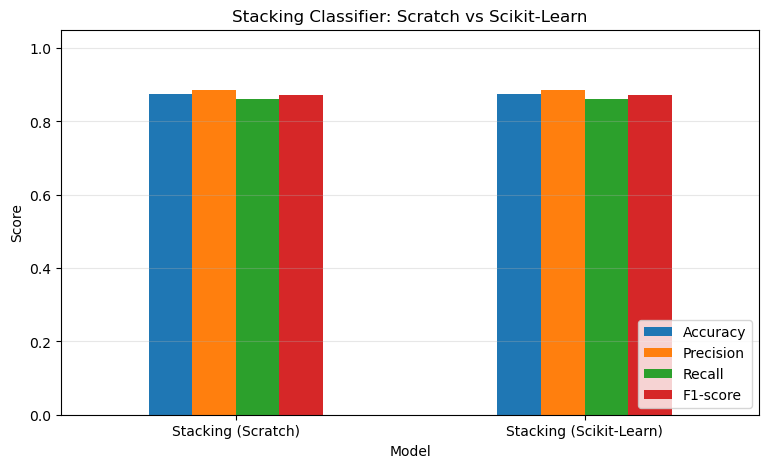

In [9]:
comparison.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Stacking Classifier: Scratch vs Scikit-Learn")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.show()

In [10]:
meta_coefficients = pd.DataFrame({
    "Base Model": [name for name, _ in base_models],
    "Coefficient": stacking_scratch.meta_model_.coef_[0]
})

meta_coefficients

,Base Model,Coefficient
0,knn,4.889215
1,tree,1.647346
2,logistic,0.710161


## Key Takeaways

- Stacking combines different models through a meta-model.
- Out-of-fold predictions help prevent training-data leakage.
- The meta-model learns how to combine base-model predictions.
- Stacking may improve performance, but improvement is not guaranteed.
- Scikit-Learn provides a convenient implementation for practical projects.